# Lab: Bayesian Belief Network (BBN), built from scratch

**Goal:** use a patient's details to find the **probability of diabetes**. The BBN is written from scratch (NumPy and Pandas only, no BBN library).

**What is a BBN?** It is a **graph** where
* each **node** is a variable (Age, BMI, Glucose, ...)
* each **arrow** means "this variable directly affects that variable"
* each node has a **CPT** (Conditional Probability Table): the probability of that node for every combination of its parents' values.

It is called a "belief" network because when we get new evidence we **update our belief (probability)**.

**You need:** `patient_data.csv` in the same folder as this notebook.

In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
raw = pd.read_csv("patient_data.csv")
print("Shape:", raw.shape)
print("Share of diabetes (1): {:.1%}".format(raw["Outcome"].mean()))
raw.head()

Shape: (1000, 7)
Share of diabetes (1): 30.3%


   Age   BMI  BloodPressure  Glucose  FamilyHistory  Smoker  Outcome
0   49  20.7             98       70              0       1        0
1   30  30.3            103       87              0       1        0
2   56  23.8            100       96              0       0        1
3   58  28.2            100       95              0       0        0
4   20  21.2             99       60              0       1        0

## Step 1: Train / test split and discretization

A BBN works with **discrete** values. So we split `Age`, `BMI`, `BloodPressure` and `Glucose` into **Low / Medium / High**.
The cut points are the 33% and 67% **quantiles** of the train data, so each group gets about the same amount of data.
`FamilyHistory`, `Smoker` and `Outcome` are already 0/1.

In [2]:
CONTINUOUS = ["Age", "BMI", "BloodPressure", "Glucose"]
LABELS = ["Low", "Medium", "High"]


def stratified_split(df, target, test_size=0.2, seed=SEED):
    rng = np.random.default_rng(seed)
    test_idx = []
    for cls in df[target].unique():
        idx = df.index[df[target] == cls].to_numpy().copy()
        rng.shuffle(idx)
        test_idx.extend(idx[: int(round(len(idx) * test_size))])
    test = df.loc[test_idx]
    train = df.drop(index=test_idx)
    return train.reset_index(drop=True), test.reset_index(drop=True)


class QuantileDiscretizer:
    # Makes 3 groups using the 33% and 67% quantiles of the train data
    def fit(self, df, columns):
        self.cuts_ = {c: np.quantile(df[c], [1 / 3, 2 / 3]) for c in columns}
        return self

    def transform(self, df):
        out = df.copy()
        for c, cuts in self.cuts_.items():
            idx = np.digitize(df[c].to_numpy(), cuts)        # 0, 1, 2
            out[c] = [LABELS[i] for i in idx]
        for c in ["FamilyHistory", "Smoker", "Outcome"]:
            out[c] = out[c].astype(int).astype(str)           # "0" / "1"
        return out


train_raw, test_raw = stratified_split(raw, "Outcome", 0.2)
print(f"Train: {len(train_raw)} rows | Test: {len(test_raw)} rows")

disc = QuantileDiscretizer().fit(train_raw, CONTINUOUS)
print("\nCut points (Low | Medium | High):")
for c, cuts in disc.cuts_.items():
    print(f"  {c:<14} Low < {cuts[0]:.1f} <= Medium < {cuts[1]:.1f} <= High")

train, test = disc.transform(train_raw), disc.transform(test_raw)
train.head()

Train: 800 rows | Test: 200 rows

Cut points (Low | Medium | High):
  Age            Low < 39.0 <= Medium < 50.0 <= High
  BMI            Low < 21.4 <= Medium < 24.8 <= High
  BloodPressure  Low < 101.0 <= Medium < 109.0 <= High
  Glucose        Low < 84.0 <= Medium < 98.0 <= High


      Age     BMI BloodPressure Glucose FamilyHistory Smoker Outcome
0  Medium     Low           Low     Low             0      1       0
1     Low    High        Medium  Medium             0      1       0
2    High  Medium           Low  Medium             0      0       1
3    High    High           Low  Medium             0      0       0
4     Low     Low           Low     Low             0      1       0

## Step 2: The network structure (DAG)

We chose the structure ourselves using domain knowledge (the way a doctor would think):

| Node | Parents |
|---|---|
| Age, FamilyHistory, Smoker | none |
| BMI | Age |
| BloodPressure | Age, BMI, Smoker |
| Glucose | Age, BMI, FamilyHistory |
| Outcome | Glucose, BMI, FamilyHistory |

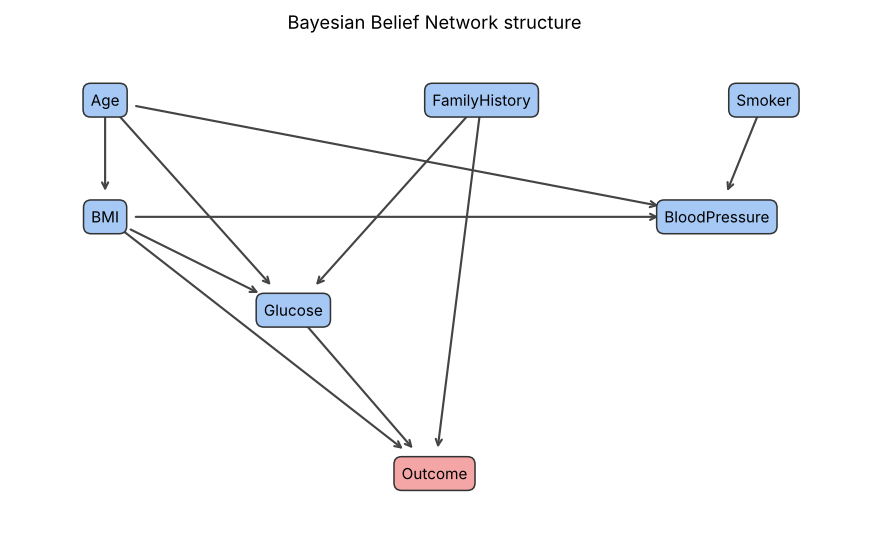

In [3]:
STRUCTURE = {
    "Age": [],
    "FamilyHistory": [],
    "Smoker": [],
    "BMI": ["Age"],
    "BloodPressure": ["Age", "BMI", "Smoker"],
    "Glucose": ["Age", "BMI", "FamilyHistory"],
    "Outcome": ["Glucose", "BMI", "FamilyHistory"],
}


def draw_network(structure):
    pos = {
        "Age": (0.0, 3.0), "FamilyHistory": (4.0, 3.0), "Smoker": (7.0, 3.0),
        "BMI": (0.0, 1.5), "BloodPressure": (6.5, 1.5),
        "Glucose": (2.0, 0.3), "Outcome": (3.5, -1.8),
    }
    fig, ax = plt.subplots(figsize=(8, 5))
    boxes = {}
    for n, (x, y) in pos.items():
        color = "#f4a6a6" if n == "Outcome" else "#a6c8f4"
        boxes[n] = ax.text(x, y, n, ha="center", va="center", fontsize=10, zorder=3,
                           bbox=dict(boxstyle="round,pad=0.5", fc=color, ec="#333"))
    for child, parents in structure.items():
        for p in parents:
            ax.annotate("", xy=pos[child], xytext=pos[p], zorder=1,
                        arrowprops=dict(arrowstyle="->", lw=1.4, color="#444",
                                        patchA=boxes[p].get_bbox_patch(),
                                        patchB=boxes[child].get_bbox_patch(),
                                        shrinkA=2, shrinkB=2))
    ax.set_xlim(-1, 8)
    ax.set_ylim(-2.5, 3.8)
    ax.axis("off")
    ax.set_title("Bayesian Belief Network structure")
    fig.tight_layout()
    plt.show()


draw_network(STRUCTURE)

## Step 3: Splitting the joint probability

The probability of the whole network is the **product** of all the CPTs:

```
P(X1, ..., Xn) = PRODUCT over i of  P( Xi | Parents(Xi) )
```

For this network:

```
P(Age, Fam, Smk, BMI, BP, Glu, Out) =
    P(Age) * P(Fam) * P(Smk)
  * P(BMI | Age)
  * P(BP  | Age, BMI, Smk)
  * P(Glu | Age, BMI, Fam)
  * P(Out | Glu, BMI, Fam)
```

This works because each variable is **conditionally independent** of the others once its parents are known.
A full joint table would have 3x3x3x3x2x2x2 = 648 entries. This way the tables stay small.

## Step 4: Parameter learning (CPTs by counting)

```
P(X = x | parents = pa) = ( count(x, pa) + 1 ) / ( count(pa) + |X| )
```

This is **MLE + Laplace smoothing (alpha = 1)**. The "+1" is there so that a combination never seen in the training data does not get probability 0 (which would make the whole product 0).

## Step 5: Inference (exact, by enumeration)

Question: `P(Outcome | evidence)`.
1. Variables that are neither the query nor in the evidence are called **hidden**.
2. For each value of the query, **add up** the joint probability over **all combinations** of the hidden variables.
3. **Normalize** so the total is 1.

In [4]:
class BayesianNetwork:
    def __init__(self, structure, alpha=1.0):
        self.structure = structure
        self.alpha = alpha          # Laplace smoothing
        self.states = {}            # node -> possible values
        self.cpt = {}               # node -> {parent_values_tuple: {value: prob}}
        self.order = self._topological_order()

    def _topological_order(self):
        order, seen = [], set()

        def visit(n):
            if n in seen:
                return
            for p in self.structure[n]:
                visit(p)
            seen.add(n)
            order.append(n)

        for n in self.structure:
            visit(n)
        return order

    # ---- parameter learning: build the CPTs by counting ------------------
    def fit(self, df):
        for node in self.structure:
            self.states[node] = sorted(df[node].unique())

        for node, parents in self.structure.items():
            table = {}
            for combo in itertools.product(*[self.states[p] for p in parents]):
                mask = np.ones(len(df), dtype=bool)
                for p, v in zip(parents, combo):
                    mask &= (df[p] == v).to_numpy()
                subset = df.loc[mask, node]
                total = len(subset) + self.alpha * len(self.states[node])
                table[combo] = {
                    s: ((subset == s).sum() + self.alpha) / total for s in self.states[node]
                }
            self.cpt[node] = table
        return self

    # ---- joint probability of one complete assignment ---------------------
    def joint_probability(self, assignment):
        p = 1.0
        for node, parents in self.structure.items():
            combo = tuple(assignment[par] for par in parents)
            p *= self.cpt[node][combo][assignment[node]]
        return p

    # ---- exact inference by enumeration ------------------------------------
    def query(self, target, evidence=None):
        evidence = evidence or {}
        hidden = [n for n in self.structure if n != target and n not in evidence]
        result = {}
        for t_val in self.states[target]:
            total = 0.0
            for h_vals in itertools.product(*[self.states[h] for h in hidden]):
                assignment = dict(evidence)
                assignment[target] = t_val
                assignment.update(dict(zip(hidden, h_vals)))
                total += self.joint_probability(assignment)
            result[t_val] = total
        z = sum(result.values())
        return {k: v / z for k, v in result.items()}

    def predict(self, df, target="Outcome"):
        feats = [c for c in df.columns if c != target]
        preds, probs = [], []
        for _, row in df.iterrows():
            post = self.query(target, {f: row[f] for f in feats})
            preds.append(max(post, key=post.get))
            probs.append(post.get("1", 0.0))
        return np.array(preds), np.array(probs)

    def print_cpt(self, node):
        parents = self.structure[node]
        header = f"CPT: P({node} | {', '.join(parents) if parents else '-'})"
        print(header)
        print("-" * len(header))
        for combo, dist in self.cpt[node].items():
            lhs = ", ".join(f"{p}={v}" for p, v in zip(parents, combo)) or "(no parents)"
            rhs = "  ".join(f"{node}={s}: {pr:.3f}" for s, pr in dist.items())
            print(f"  {lhs:<45} -> {rhs}")
        print()

## Step 6: Train the network and look at the CPTs

For example, the value of `P(Outcome=1 | Glucose=High, BMI=High, FamilyHistory=1)` tells us how many such patients had diabetes.

In [5]:
bn = BayesianNetwork(STRUCTURE, alpha=1.0).fit(train)

print("Network order (parents first):", bn.order, "\n")
bn.print_cpt("Age")
bn.print_cpt("BMI")
bn.print_cpt("Outcome")

Network order (parents first): ['Age', 'FamilyHistory', 'Smoker', 'BMI', 'BloodPressure', 'Glucose', 'Outcome'] 

CPT: P(Age | -)
---------------
  (no parents)                                  -> Age=High: 0.344  Age=Low: 0.318  Age=Medium: 0.339

CPT: P(BMI | Age)
-----------------
  Age=High                                      -> BMI=High: 0.410  BMI=Low: 0.245  BMI=Medium: 0.345
  Age=Low                                       -> BMI=High: 0.241  BMI=Low: 0.420  BMI=Medium: 0.339
  Age=Medium                                    -> BMI=High: 0.358  BMI=Low: 0.332  BMI=Medium: 0.310

CPT: P(Outcome | Glucose, BMI, FamilyHistory)
---------------------------------------------
  Glucose=High, BMI=High, FamilyHistory=0       -> Outcome=0: 0.304  Outcome=1: 0.696
  Glucose=High, BMI=High, FamilyHistory=1       -> Outcome=0: 0.193  Outcome=1: 0.807
  Glucose=High, BMI=Low, FamilyHistory=0        -> Outcome=0: 0.632  Outcome=1: 0.368
  Glucose=High, BMI=Low, FamilyHistory=1        -> Outcome

### Sanity check: are the probabilities correct?

* The joint probabilities of all possible assignments must add up to **1**.
* A posterior must also add up to **1**.

In [6]:
nodes = list(STRUCTURE)
total = sum(bn.joint_probability(dict(zip(nodes, v)))
            for v in itertools.product(*[bn.states[n] for n in nodes]))
print("Sum of all joint probabilities =", round(total, 10))

post = bn.query("Outcome", {"Glucose": "High", "BMI": "High"})
print("Posterior:", {k: round(float(v), 3) for k, v in post.items()}, "| sum =", round(sum(post.values()), 10))

Sum of all joint probabilities = 1.0
Posterior: {'0': 0.261, '1': 0.739} | sum = 1.0


## Step 7: Inference examples (belief update)

See how `P(Outcome=1)` is **updated** as we add more evidence.

In [7]:
queries = [
    ("No evidence (prior)", {}),
    ("Glucose=High", {"Glucose": "High"}),
    ("Glucose=High, BMI=High", {"Glucose": "High", "BMI": "High"}),
    ("Glucose=High, BMI=High, FamilyHistory=1",
     {"Glucose": "High", "BMI": "High", "FamilyHistory": "1"}),
    ("Glucose=Low, BMI=Low, FamilyHistory=0",
     {"Glucose": "Low", "BMI": "Low", "FamilyHistory": "0"}),
]

print("P(Outcome=1 | evidence)")
for name, ev in queries:
    print(f"  {name:<42} -> {bn.query('Outcome', ev)['1']:.3f}")

P(Outcome=1 | evidence)
  No evidence (prior)                        -> 0.310
  Glucose=High                               -> 0.645
  Glucose=High, BMI=High                     -> 0.739
  Glucose=High, BMI=High, FamilyHistory=1    -> 0.807
  Glucose=Low, BMI=Low, FamilyHistory=0      -> 0.039


### Reverse (diagnostic) reasoning

A special strength of the BBN: it can reason from effect back to cause.
Question: "If a patient has diabetes, what is the glucose level likely to be?" That is `P(Glucose | Outcome=1)`.

In [8]:
print("P(Glucose | Outcome=1)")
for k, v in bn.query("Glucose", {"Outcome": "1"}).items():
    print(f"  Glucose={k:<7} {v:.3f}")

print("\nP(BloodPressure | Smoker)")
for s in ["0", "1"]:
    post = bn.query("BloodPressure", {"Smoker": s})
    print(f"  Smoker={s}: " + "  ".join(f"BP={k}: {v:.3f}" for k, v in post.items()))

P(Glucose | Outcome=1)
  Glucose=High    0.740
  Glucose=Low     0.059
  Glucose=Medium  0.201

P(BloodPressure | Smoker)
  Smoker=0: BP=High: 0.348  BP=Low: 0.336  BP=Medium: 0.316
  Smoker=1: BP=High: 0.385  BP=Low: 0.276  BP=Medium: 0.339


## Step 8: Test on the test set

For each test patient we use the other 6 features as **evidence** and compute `P(Outcome=1 | ...)`. If it is above 0.5, we predict "Diabetes".

Accuracy=0.855  Precision=0.742  Recall=0.803  F1=0.772

Confusion matrix (rows = actual, cols = predicted)
                 Pred 0   Pred 1
  Actual 0 (No)     122       17
  Actual 1 (Yes)     12       49


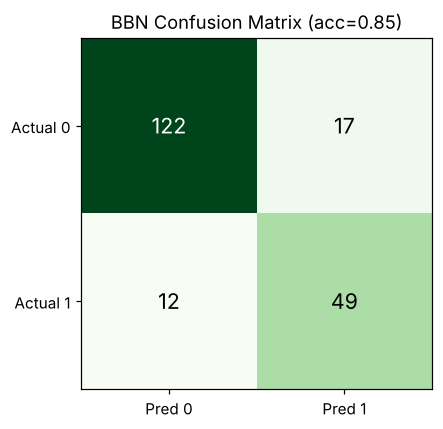

In [9]:
def confusion_matrix(y_true, y_pred):
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    return np.array([[tn, fp], [fn, tp]])


def report(y_true, y_pred):
    (tn, fp), (fn, tp) = confusion_matrix(y_true, y_pred)
    acc = (tp + tn) / len(y_true)
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    rec = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
    return acc, prec, rec, f1


y_true = test["Outcome"].astype(int).to_numpy()
y_pred_s, prob = bn.predict(test)
y_pred = y_pred_s.astype(int)

acc, prec, rec, f1 = report(y_true, y_pred)
cm = confusion_matrix(y_true, y_pred)

print(f"Accuracy={acc:.3f}  Precision={prec:.3f}  Recall={rec:.3f}  F1={f1:.3f}")
print("\nConfusion matrix (rows = actual, cols = predicted)")
print("                 Pred 0   Pred 1")
print(f"  Actual 0 (No)  {cm[0,0]:>6}   {cm[0,1]:>6}")
print(f"  Actual 1 (Yes) {cm[1,0]:>6}   {cm[1,1]:>6}")

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Greens")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
ax.set_xticks([0, 1], ["Pred 0", "Pred 1"])
ax.set_yticks([0, 1], ["Actual 0", "Actual 1"])
ax.set_title(f"BBN Confusion Matrix (acc={acc:.2f})")
fig.tight_layout()
plt.show()

## Conclusion

* Belief is updated as evidence is added (from about 0.31 up to 0.81).
* A BBN gives **real probabilities**, not just a hard label.
* Missing values are easy: leave the unknown feature out of the evidence and it becomes hidden, so it is summed out.
* **Reverse reasoning** (from effect to cause) is possible, which KNN cannot do.

**Weaknesses:** the structure needs domain knowledge, number data must be grouped (some information is lost),
and enumeration is slow for very large networks (those use Variable Elimination or sampling).

**What to try next:** learn the structure from data (Hill-Climbing with a BIC score), use a real dataset (Pima Indians Diabetes),
and compare with KNN using cross-validation.